# **Analysis** 

In [1]:
import pandas as pd
#this is a comment from the other guy

df = pd.read_csv("customers_sales.csv")

,customer_name,customer_branch,file_name,order_quantity
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800


In [29]:
# Give every row a unique ID because of duplicates
df["record_id"] = range(1, len(df) + 1)

# Standardize customer names
df["customer_name"] = df["customer_name"].str.strip()

df["customer_name"] = df["customer_name"].replace({
    "AutoPart AG": "AutoParts AG",
    "Metalform SA": "MetalForm SA"
})

# Check customers
print(df["customer_name"].unique())


<StringArray>
['MetalForm SA', 'AutoParts AG', 'PrecisionCut GmbH', 'TechFab Industries']
Length: 4, dtype: str


In [3]:

customer_stats = df.groupby("customer_name").agg(
    number_of_entries=("order_quantity", "count"),
    unique_designs=("file_name", "nunique"),
    total_quantity=("order_quantity", "sum"),
    mean=("order_quantity", "mean"),
    median=("order_quantity", "median"),
    std=("order_quantity", "std"),
    minimum=("order_quantity", "min"),
    maximum=("order_quantity", "max")
)

display(customer_stats.round(2))


,number_of_entries,unique_designs,total_quantity,mean,median,std,minimum,maximum
customer_name,,,,,,,,
AutoParts AG,34,32,286900,8438.24,8700.0,919.41,6100,9800
MetalForm SA,13,13,17300,1330.77,1250.0,504.78,500,2100
PrecisionCut GmbH,21,19,110950,5283.33,4800.0,1473.54,3750,7800
TechFab Industries,11,11,184000,16727.27,17800.0,2959.25,12050,19700


In [30]:
# Group order quantities by customer
groups = df.groupby("customer_name")["order_quantity"]

# First and third quartiles
customer_stats["Q1"] = groups.quantile(0.25)
customer_stats["Q3"] = groups.quantile(0.75)

# Interquartile range
customer_stats["IQR"] = customer_stats["Q3"] - customer_stats["Q1"]

customer_stats["skewness"] = groups.skew()
customer_stats["kurtosis"] = groups.apply(pd.Series.kurt)

display(customer_stats.round(2))



,number_of_entries,unique_designs,total_quantity,mean,median,std,minimum,maximum,Q1,Q3,IQR,share_percent,skewness,kurtosis
customer_name,,,,,,,,,,,,,,
AutoParts AG,34,32,286900,8438.24,8700.0,919.41,6100,9800,7900.0,9075.0,1175.0,47.88,-0.72,0.13
TechFab Industries,11,11,184000,16727.27,17800.0,2959.25,12050,19700,14250.0,19400.0,5150.0,30.71,-0.48,-1.58
PrecisionCut GmbH,21,19,110950,5283.33,4800.0,1473.54,3750,7800,4000.0,6600.0,2600.0,18.52,0.60,-1.25
MetalForm SA,13,13,17300,1330.77,1250.0,504.78,500,2100,1050.0,1800.0,750.0,2.89,-0.03,-1.14


In [32]:
customer_stats["share_percent"] = (
    customer_stats["total_quantity"]
    / customer_stats["total_quantity"].sum()
    * 100
)

# Sort customers from largest to smallest total quantity
customer_stats = customer_stats.sort_values(
    "total_quantity", ascending=False
)

display(customer_stats.round(2))


,number_of_entries,unique_designs,total_quantity,mean,median,std,minimum,maximum,Q1,Q3,IQR,share_percent,skewness,kurtosis
customer_name,,,,,,,,,,,,,,
AutoParts AG,34,32,286900,8438.24,8700.0,919.41,6100,9800,7900.0,9075.0,1175.0,47.88,-0.72,0.13
TechFab Industries,11,11,184000,16727.27,17800.0,2959.25,12050,19700,14250.0,19400.0,5150.0,30.71,-0.48,-1.58
PrecisionCut GmbH,21,19,110950,5283.33,4800.0,1473.54,3750,7800,4000.0,6600.0,2600.0,18.52,0.60,-1.25
MetalForm SA,13,13,17300,1330.77,1250.0,504.78,500,2100,1050.0,1800.0,750.0,2.89,-0.03,-1.14


In [33]:
branch_stats = df.groupby(
    ["customer_name", "customer_branch"]
).agg(
    number_of_entries=("order_quantity", "count"),
    unique_designs=("file_name", "nunique"),
    total_quantity=("order_quantity", "sum"),
    mean=("order_quantity", "mean"),
    median=("order_quantity", "median")
)


branch_groups = df.groupby(
    ["customer_name", "customer_branch"]
)["order_quantity"]

branch_stats["Q1"] = branch_groups.quantile(0.25)
branch_stats["Q3"] = branch_groups.quantile(0.75)
branch_stats["IQR"] = branch_stats["Q3"] - branch_stats["Q1"]

display(branch_stats.round(2))


number_of_entries  unique_designs  \
customer_name      customer_branch                                       
AutoParts AG       Berlin Branch                    15              14   
                   Munich Branch                    19              18   
MetalForm SA       Frankfurt Branch                 13              13   
PrecisionCut GmbH  Stuttgart Branch                 21              19   
TechFab Industries Hamburg Branch                   11              11   

                                     total_quantity      mean   median  \
customer_name      customer_branch                                       
AutoParts AG       Berlin Branch             118350   7890.00   7900.0   
                   Munich Branch             168550   8871.05   9000.0   
MetalForm SA       Frankfurt Branch           17300   1330.77   1250.0   
PrecisionCut GmbH  Stuttgart Branch          110950   5283.33   4800.0   
TechFab Industries Hamburg Branch            184000  16727.27  17800.0   

                                          Q1       Q3     IQR  
customer_name      customer_branch                             
AutoParts AG       Berlin Branch      7550.0   8600.0  1050.0  
                   Munich Branch      8575.0   9375.0   800.0  
MetalForm SA       Frankfurt Branch   1050.0   1800.0   750.0  
PrecisionCut GmbH  Stuttgart Branch   4000.0   6600.0  2600.0  
TechFab Industries Hamburg Branch    14250.0  19400.0  5150.0

# **Visualization**

In [16]:
import matplotlib.pyplot as plt

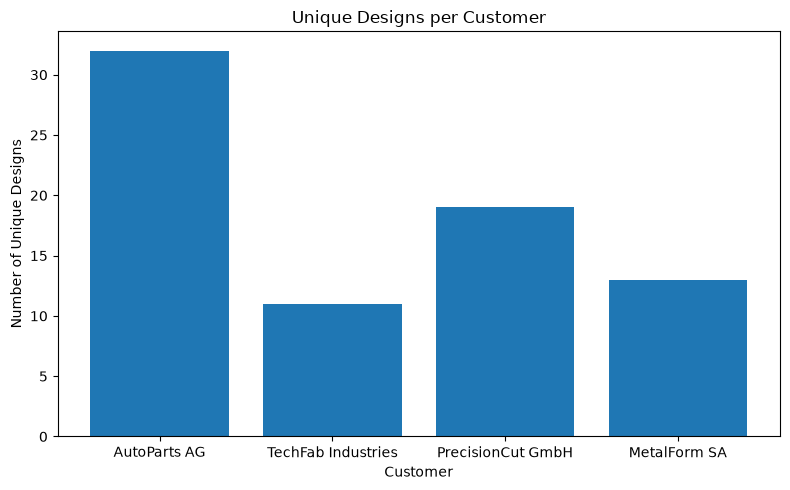

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(customer_stats.index, customer_stats["unique_designs"])

plt.title("Unique Designs per Customer")
plt.xlabel("Customer")
plt.ylabel("Number of Unique Designs")


plt.tight_layout()
plt.show()

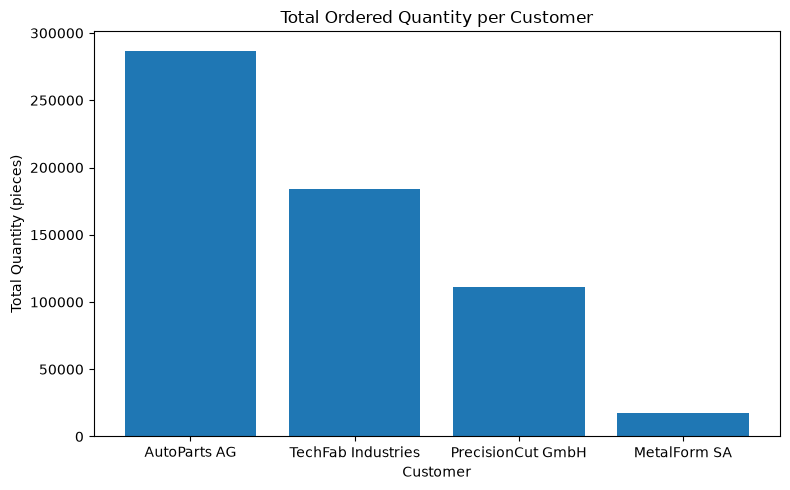

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(customer_stats.index, customer_stats["total_quantity"])

plt.title("Total Ordered Quantity per Customer")
plt.xlabel("Customer")
plt.ylabel("Total Quantity (pieces)")


plt.tight_layout()
plt.show()


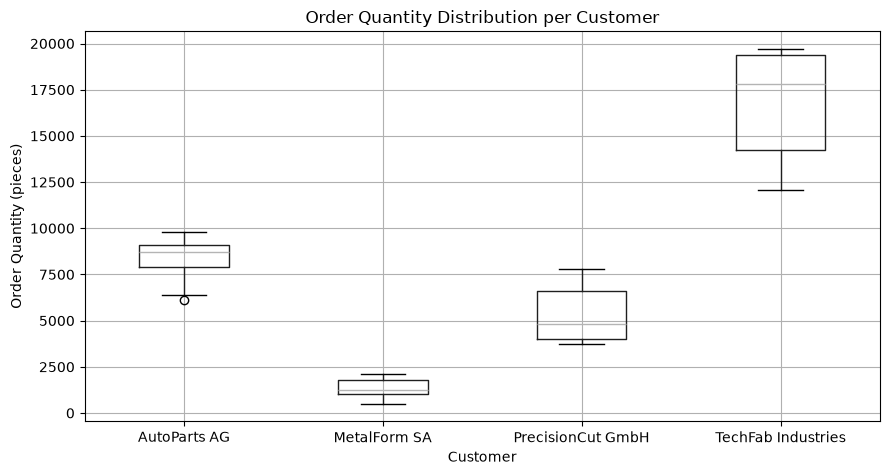

In [26]:
df.boxplot(
    column="order_quantity",
    by="customer_name",
    figsize=(9, 5)
)

plt.title("Order Quantity Distribution per Customer")
plt.suptitle("")
plt.xlabel("Customer")
plt.ylabel("Order Quantity (pieces)")


plt.tight_layout()
plt.show()


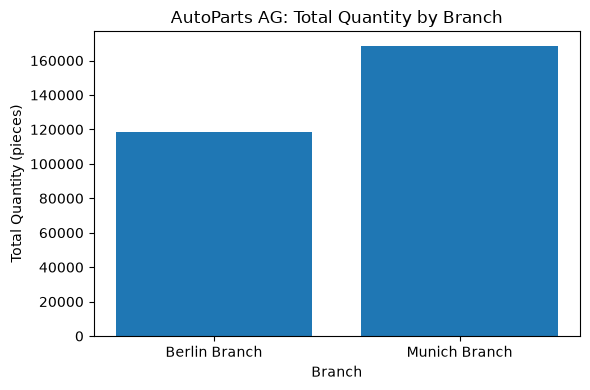

In [23]:
autoparts_stats = branch_stats.loc["AutoParts AG"]

plt.figure(figsize=(6, 4))

plt.bar(
    autoparts_stats.index,
    autoparts_stats["total_quantity"]
)

plt.title("AutoParts AG: Total Quantity by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Quantity (pieces)")

plt.tight_layout()
plt.show()


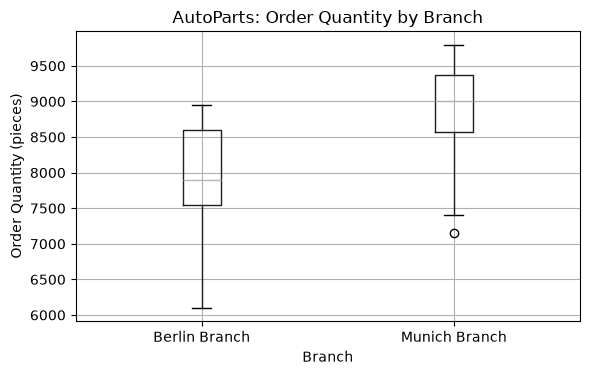

In [24]:
autoparts = df[df["customer_name"] == "AutoParts AG"]

autoparts.boxplot(
    column="order_quantity",
    by="customer_branch",
    figsize=(6, 4)
)

plt.title("AutoParts: Order Quantity by Branch")
plt.suptitle("")
plt.xlabel("Branch")
plt.ylabel("Order Quantity (pieces)")

plt.tight_layout()
plt.show()


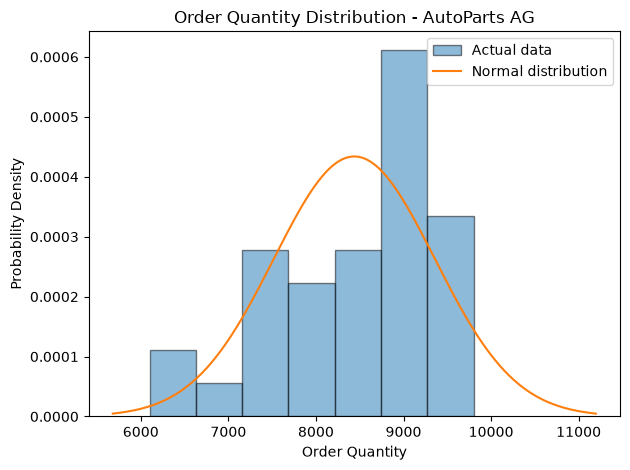

In [31]:
import math

# Select one customer
quantities = df.loc[
    df["customer_name"] == "AutoParts AG",
    "order_quantity"
]

# Calculate mean and standard deviation
mean = quantities.mean()
std = quantities.std()

# Create x-values for the normal curve
x = [mean - 3*std + i*6*std/200 for i in range(201)]

# Calculate normal distribution density
y = [
    math.exp(-0.5*((v-mean)/std)**2)
    / (std*math.sqrt(2*math.pi))
    for v in x
]

# Plot actual distribution
plt.hist(quantities, bins=7, density=True,
         alpha=0.5, edgecolor="black",
         label="Actual data")

# Overlay normal distribution
plt.plot(x, y, label="Normal distribution")

plt.title("Order Quantity Distribution - AutoParts AG")
plt.xlabel("Order Quantity")
plt.ylabel("Probability Density")
plt.legend()
plt.tight_layout()
plt.show()


# Main Findings


**1. Customer structure**
- AutoParts AG has the largest total ordered quantity (**47.9%**) and the most unique designs (**32**).
- TechFab Industries contributes **30.7%** of the total quantity despite having only **11 unique designs**.
- MetalForm SA has the smallest share (**2.9%**).

**2. Order quantity distribution**
- TechFab has the highest mean (**16,727 pieces**) and median (**17,800 pieces**) per entry, suggesting larger typical quantities.
- Differences between mean and median, as well as the standard deviation and IQR, help identify variation in ordering patterns.
- The boxplots allow comparison of the distributions and potential outliers.

**3. AutoParts AG – Branch comparison**
- Munich has a higher total ordered quantity (**168,550 pieces**) than Berlin (**118,350 pieces**).
- Munich also has more unique designs (**18 vs. 14**) and a higher median quantity (**9,000 vs. 7,900 pieces**).

**4. Limitations**
- Four pairs of identical records were retained because they may represent separate orders.
- The dataset does not include order dates or prices, so ordering frequency and actual revenue cannot be determined.
- Customer ordering patterns alone cannot establish actual cutting or retrieval times.